# EDA: Default of Credit Card Clients

Разведочный анализ датасета для PD-модели (предсказание дефолта).

**Цель:** понять структуру данных, распределение таргета, ключевые признаки и
обосновать Feature Engineering.

**Датасет:** 30 000 клиентов кредитных карт (Тайвань). Таргет —
`default.payment.next.month` (1 = дефолт в следующем месяце).

Ключевые группы признаков:
- `PAY_0 … PAY_6` — статус оплаты за 6 последних месяцев (новое → старое):
  `-2` нет записи, `-1` полностью погашено, `0` в срок, `1…8` просрочка (мес.)
- `BILL_AMT1…6` — выставленные суммы, `PAY_AMT1…6` — суммы предыдущего платежа
- `LIMIT_BAL`, `AGE`, `SEX`, `EDUCATION`, `MARRIAGE` — демография и лимит


In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# корень проекта = каталог, содержащий src/ (ноутбук лежит в notebooks/)
_here = Path('.').resolve()
ROOT = _here if (_here / 'src').is_dir() else _here.parent
sys.path.insert(0, str(ROOT))
from src.data.load import load_raw, clean, TARGET, PAY_COLS, BILL_COLS, PAYAMT_COLS

plt.rcParams['figure.figsize'] = (10, 5)
pd.set_option('display.max_columns', None)

df = load_raw()
print('raw shape:', df.shape)
df.info()


raw shape: (30000, 25)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   ID                          30000 non-null  int64  
 1   LIMIT_BAL                   30000 non-null  float64
 2   SEX                         30000 non-null  int64  
 3   EDUCATION                   30000 non-null  int64  
 4   MARRIAGE                    30000 non-null  int64  
 5   AGE                         30000 non-null  int64  
 6   PAY_0                       30000 non-null  int64  
 7   PAY_2                       30000 non-null  int64  
 8   PAY_3                       30000 non-null  int64  
 9   PAY_4                       30000 non-null  int64  
 10  PAY_5                       30000 non-null  int64  
 11  PAY_6                       30000 non-null  int64  
 12  BILL_AMT1                   30000 non-null  float64
 13  BILL_AMT

In [2]:
# Чистим: убираем ID и строки с пропусками
dfc = clean(df)
print('clean shape:', dfc.shape, '| dropped:', len(df) - len(dfc))
print('nulls after clean:', int(dfc.isnull().sum().sum()))


clean shape: (30000, 24) | dropped: 0
nulls after clean: 0


default.payment.next.month
0    23364
1     6636
Name: count, dtype: int64

Доля дефолтов: 22.12%


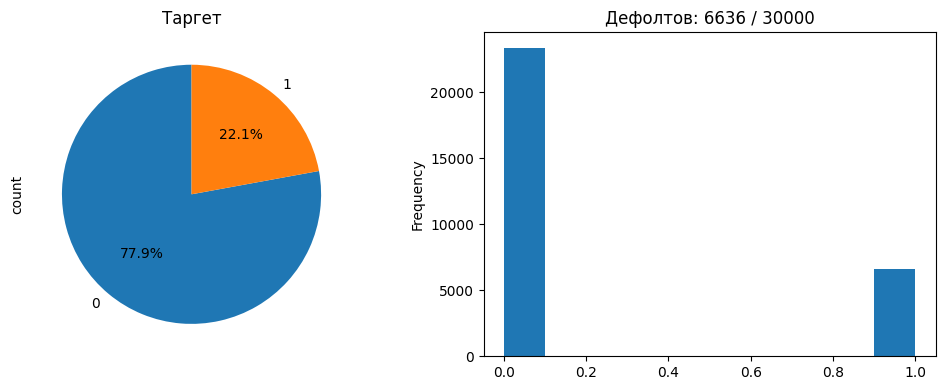

In [3]:
# Распределение таргета
vc = dfc[TARGET].value_counts()
print(vc)
print(f"\nДоля дефолтов: {vc[1]/len(dfc):.2%}")
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
vc.plot.pie(ax=ax[0], autopct='%1.1f%%', startangle=90)
ax[0].set_title('Таргет')
dfc[TARGET].plot.hist(ax=ax[1])
ax[1].set_title(f'Дефолтов: {int(vc[1])} / {len(dfc)}')
plt.tight_layout(); plt.show()


In [4]:
# Базовая статистика числовых признаков
num = dfc.drop(columns=[TARGET, 'SEX', 'EDUCATION', 'MARRIAGE'])
num.describe().T[['mean', '50%', 'min', 'max', 'std']]


,mean,50%,min,max,std
LIMIT_BAL,167484.322667,140000.0,10000.0,1000000.0,129747.661567
AGE,35.485500,34.0,21.0,79.0,9.217904
PAY_0,-0.016700,0.0,-2.0,8.0,1.123802
PAY_2,-0.133767,0.0,-2.0,8.0,1.197186
PAY_3,-0.166200,0.0,-2.0,8.0,1.196868
PAY_4,-0.220667,0.0,-2.0,8.0,1.169139
PAY_5,-0.266200,0.0,-2.0,8.0,1.133187
PAY_6,-0.291100,0.0,-2.0,8.0,1.149988
BILL_AMT1,51223.330900,22381.5,-165580.0,964511.0,73635.860576
BILL_AMT2,49179.075167,21200.0,-69777.0,983931.0,71173.768783


In [5]:
# Категориальные признаки
for c in ['SEX', 'EDUCATION', 'MARRIAGE']:
    print(f'--- {c} ---')
    print(dfc[c].value_counts().sort_index())
    print()


--- SEX ---
SEX
1    11888
2    18112
Name: count, dtype: int64

--- EDUCATION ---
EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64

--- MARRIAGE ---
MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64



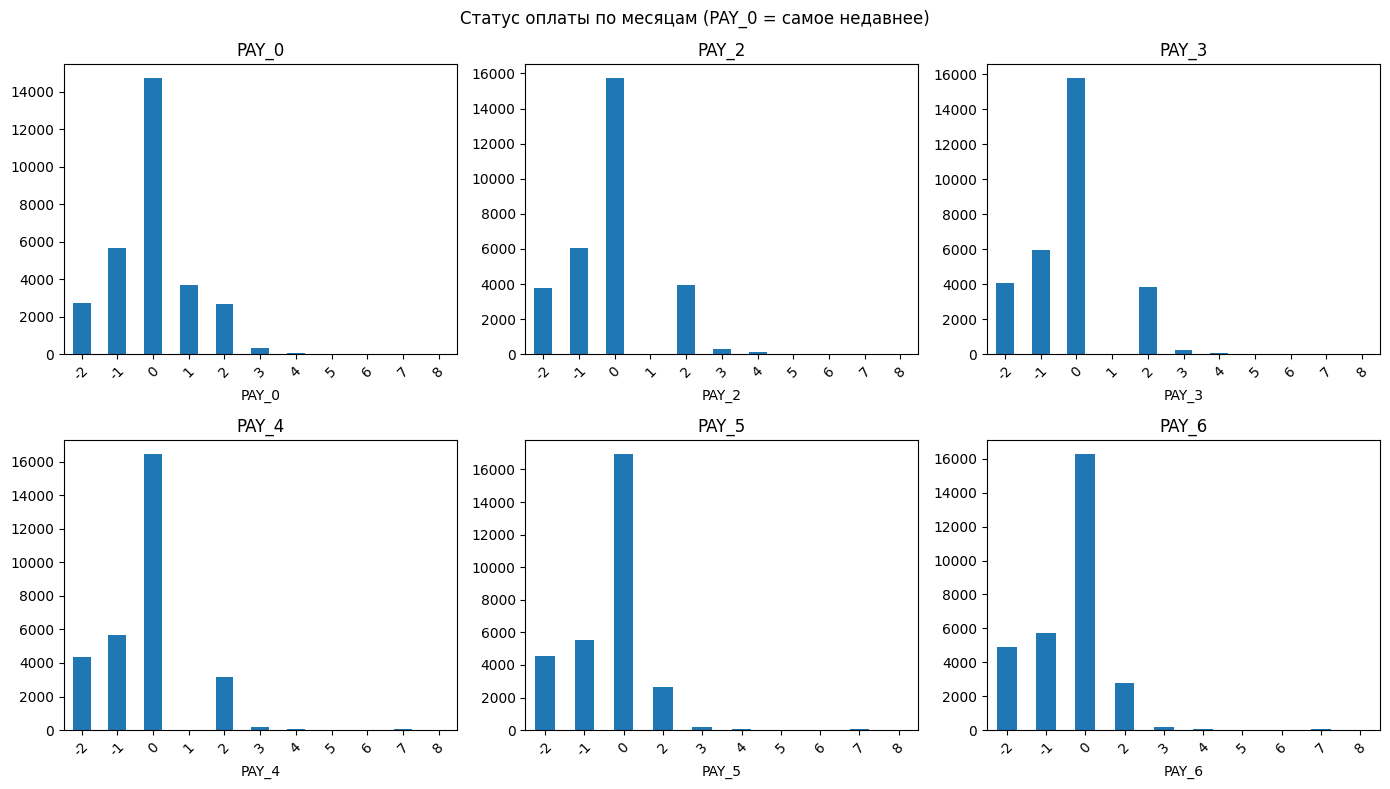

In [6]:
# Статусы оплаты: распределение по месяцам
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, c in zip(axes.ravel(), PAY_COLS):
    dfc[c].value_counts().sort_index().plot.bar(ax=ax)
    ax.set_title(c)
    ax.tick_params(axis='x', labelrotation=45)
plt.suptitle('Статус оплаты по месяцам (PAY_0 = самое недавнее)')
plt.tight_layout(); plt.show()


default.payment.next.month      0      1  default_rate
PAY_0                                                 
-2                          0.868  0.132         0.132
-1                          0.832  0.168         0.168
 0                          0.872  0.128         0.128
 1                          0.661  0.339         0.339
 2                          0.309  0.691         0.691
 3                          0.242  0.758         0.758
 4                          0.316  0.684         0.684
 5                          0.500  0.500         0.500
 6                          0.455  0.545         0.545
 7                          0.222  0.778         0.778
 8                          0.421  0.579         0.579


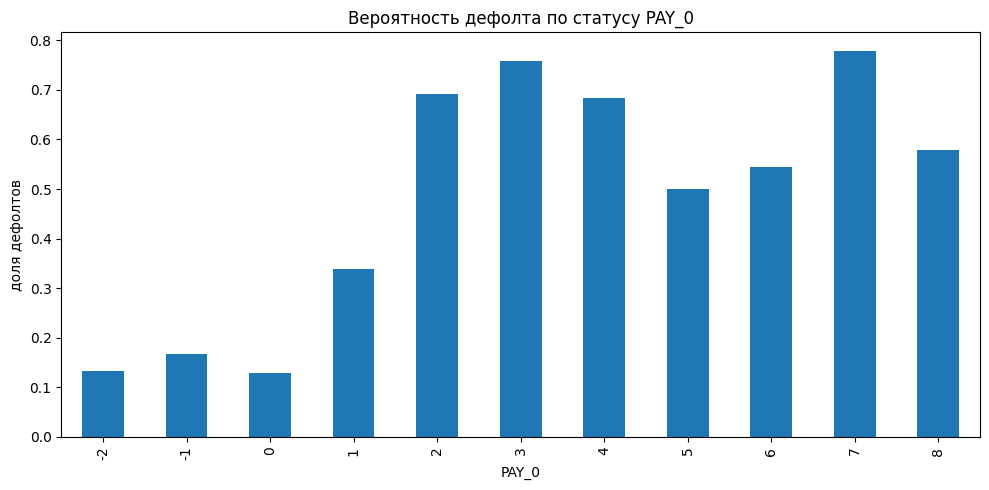

In [7]:
# Связь статуса оплаты с дефолтом (PAY_0 — самое свежее)
# crosstab: колонки = значения таргета (0/1)
ct = pd.crosstab(dfc['PAY_0'], dfc[TARGET], normalize='index')
ct['default_rate'] = ct[1]
print(ct.round(3))
ct['default_rate'].plot.bar(title='Вероятность дефолта по статусу PAY_0')
plt.ylabel('доля дефолтов'); plt.tight_layout(); plt.show()


PAY_0        0.325
PAY_2        0.264
PAY_3        0.235
PAY_4        0.217
PAY_5        0.204
PAY_6        0.187
LIMIT_BAL   -0.154
PAY_AMT1    -0.073
PAY_AMT2    -0.059
PAY_AMT4    -0.057
PAY_AMT3    -0.056
PAY_AMT5    -0.055
PAY_AMT6    -0.053
BILL_AMT1   -0.020
BILL_AMT2   -0.014
BILL_AMT3   -0.014
AGE          0.014
BILL_AMT4   -0.010
BILL_AMT5   -0.007
BILL_AMT6   -0.005
Name: default.payment.next.month, dtype: float64


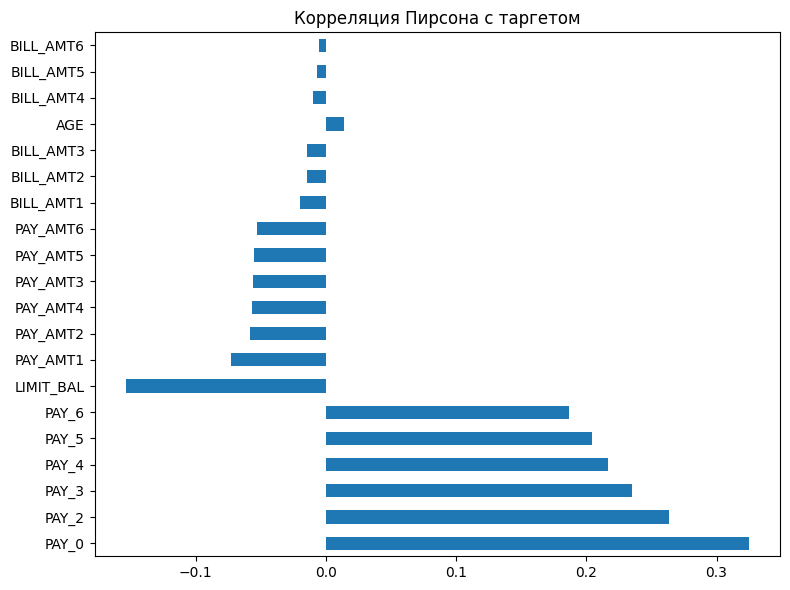

In [8]:
# Корреляции числовых признаков с таргетом
corr = num.join(dfc[TARGET]).corr()[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)
print(corr.round(3))
corr.plot.barh(title='Корреляция Пирсона с таргетом', figsize=(8, 6))
plt.tight_layout(); plt.show()


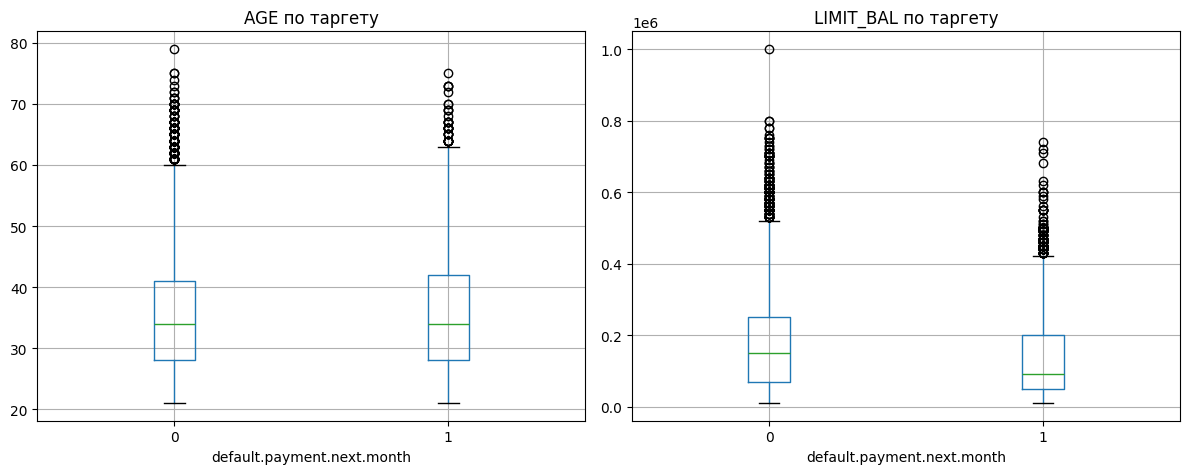

In [9]:
# Визуализация: возраст и лимит по таргету
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
dfc.boxplot(column='AGE', by=TARGET, ax=ax[0]); ax[0].set_title('AGE по таргету')
dfc.boxplot(column='LIMIT_BAL', by=TARGET, ax=ax[1]); ax[1].set_title('LIMIT_BAL по таргету')
plt.suptitle(''); plt.tight_layout(); plt.show()


## Выводы

1. **Классы несбалансированы** (~22% дефолтов) — для метрик важны Recall/F1 по
   классу дефолта, а не accuracy.
2. **Свежие статусы оплаты — главный сигнал.** Дефолт почти детерминирован
   `PAY_0`/`PAY_2`: просрочка ≥ 2 в недавнем месяце резко повышает вероятность.
3. **История платежей (PAY_*)** несёт больше информации, чем демография и лимиты.
4. **Feature Engineering** (см. `src/data/feature_engineering.py`): агрегаты по
   истории платежей (макс/средняя просрочка, число месяцев с задержкой, тренд,
   подряд идущие задержки), агрегаты по суммам (средний/максимальный счёт,
   отношение платежа к счёту), биннинг возраста, log лимита.


In [10]:
# Применяем Feature Engineering и смотрим результат
from src.data.feature_engineering import build_features, FEATURED_COLS

df_fe = build_features(dfc)
print('featured shape:', df_fe.shape)
print('новые признаки:', FEATURED_COLS)
df_fe[FEATURED_COLS].describe().T[['mean', '50%', 'min', 'max']]


featured shape: (30000, 41)
новые признаки: ['pay_max_status', 'pay_min_status', 'pay_mean_status', 'pay_std_status', 'pay_num_late', 'pay_num_severe', 'pay_num_norecord', 'pay_trend', 'pay_consec_late', 'bill_mean', 'bill_max', 'bill_trend', 'payamt_mean', 'payamt_max', 'pay_to_bill', 'age_group', 'limit_bal_log']


,mean,50%,min,max
pay_max_status,0.438733,0.000000,-2.000000,8.000000e+00
pay_min_status,-0.604800,0.000000,-2.000000,4.000000e+00
pay_mean_status,-0.182439,0.000000,-2.000000,6.000000e+00
pay_std_status,0.454326,0.408248,0.000000,3.204164e+00
pay_num_late,0.834200,0.000000,0.000000,6.000000e+00
pay_num_severe,0.710133,0.000000,0.000000,6.000000e+00
pay_num_norecord,0.813833,0.000000,0.000000,6.000000e+00
pay_trend,0.274400,0.000000,-7.000000,7.000000e+00
pay_consec_late,0.618400,0.000000,0.000000,6.000000e+00
bill_mean,44976.945200,21051.833333,-56043.166667,8.773138e+05


pay_num_severe      0.399
pay_num_late        0.398
pay_consec_late     0.371
pay_max_status      0.331
pay_mean_status     0.282
pay_std_status      0.249
limit_bal_log      -0.174
pay_min_status      0.167
pay_trend           0.129
payamt_mean        -0.102
payamt_max         -0.082
bill_max           -0.041
pay_num_norecord   -0.039
bill_trend         -0.026
bill_mean          -0.013
age_group           0.011
pay_to_bill        -0.006
Name: default.payment.next.month, dtype: float64


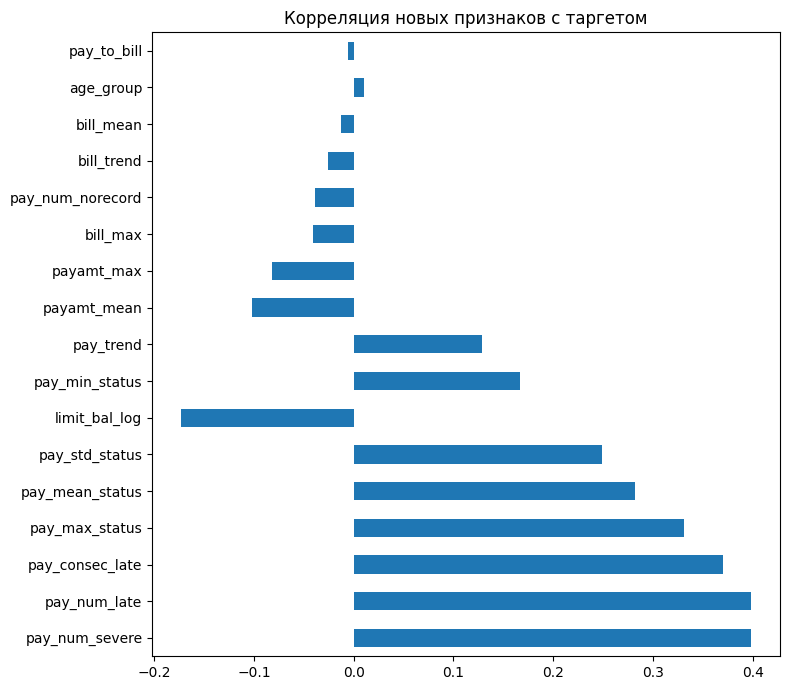

In [11]:
# Быстрая проверка: информативность новых признаков (корреляция с таргетом)
new = df_fe[FEATURED_COLS].join(dfc[TARGET]).corr()[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)
print(new.round(3))
new.plot.barh(title='Корреляция новых признаков с таргетом', figsize=(8, 7))
plt.tight_layout(); plt.show()
